## EDA. Начало.
Анализ трех TikTok [датасетов](https://huggingface.co/datasets/lingbow/tiktok-video-engagement-1m) из HuggingFace. Нужно скачать все три датасета и положить их в data/tiktok.

- Creators
- Engagement
- Videos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings

RANDOM_STATE = 67

warnings.filterwarnings('ignore')

In [2]:
df_creators = pd.read_parquet("../data/tiktok/creator_daily.parquet")
df_engagement = pd.read_parquet("../data/tiktok/engagement_daily.parquet")
df_videos = pd.read_parquet("../data/tiktok/videos.parquet")

Начнем изучать все три датасета сначало по отдельности.

### Creators
 
Это датасет, состоящий из аккаунтов пользователей Tiktok с основными статистиками: подписчики, сколько видео, и т.д.

``df_creators`` содержит несколько наблюдений для одного author_id, сделанных в разные дни. Удалять эти "дубликаты" не будем по двум причинам:

1) Мы потеряем информацию о динамике популярности автора.
2) При прогнозировании популярности видео нельзя использовать статистику автора, полученную после момента предсказания, поскольку это приведёт к утечке.

В дальнейшем будем сопоставлять каждому видео наиболее актуальную статистику автора, доступную на момент прогнозирования.

In [3]:
df_creators

,author_id,date,follower_count,following_count,total_favorited,video_count,enterprise_verified
0,1008189,2024-07-11,1168.0,432.0,1687.0,89.0,NaN
1,1008189,2024-07-12,1167.0,432.0,1693.0,90.0,NaN
2,1008189,2024-07-13,1165.0,432.0,1693.0,90.0,NaN
3,1008189,2024-07-14,1164.0,432.0,1693.0,90.0,NaN
4,1008189,2024-07-15,1164.0,433.0,1693.0,90.0,NaN
...,...,...,...,...,...,...,...
937479,984282,2025-01-14,142518.0,201.0,1870366.0,115.0,NaN
937480,984282,2025-01-15,142515.0,202.0,1870370.0,115.0,NaN
937481,984282,2025-01-16,142510.0,202.0,1870378.0,115.0,NaN
937482,984282,2025-01-17,142505.0,202.0,1870384.0,115.0,NaN


In [4]:
df_creators.shape

(937484, 7)

Количество пропущенных значений

In [5]:
df_creators.isna().sum()

author_id                   0
date                        0
follower_count           4452
following_count          4452
total_favorited          3940
video_count              5647
enterprise_verified    937449
dtype: int64

In [6]:
df_creators.dtypes

author_id                  str
date                       str
follower_count         float64
following_count        float64
total_favorited        float64
video_count            float64
enterprise_verified        str
dtype: object

Ожидаемо, что распределение кол-ва подписчиков будет скошено в сторону маленьких каналов

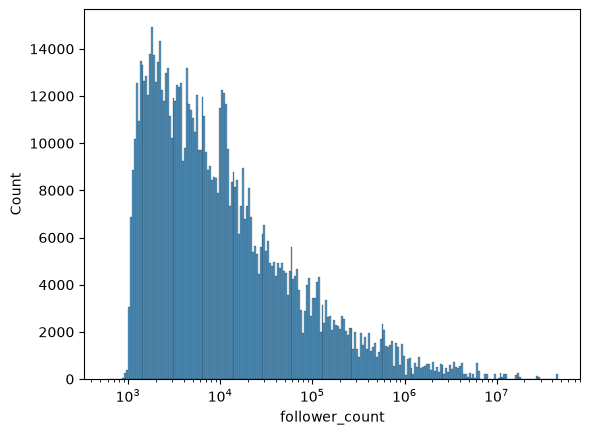

In [7]:
sns.histplot(df_creators["follower_count"], log_scale=True)
plt.show()

Заметим, что столбец enterprise_verified не содержит ни одного Not Null значения. Дропнем его

In [8]:
df_creators["enterprise_verified"].isna().sum()
df_creators = df_creators.drop(columns=["enterprise_verified"])

df_creators

,author_id,date,follower_count,following_count,total_favorited,video_count
0,1008189,2024-07-11,1168.0,432.0,1687.0,89.0
1,1008189,2024-07-12,1167.0,432.0,1693.0,90.0
2,1008189,2024-07-13,1165.0,432.0,1693.0,90.0
3,1008189,2024-07-14,1164.0,432.0,1693.0,90.0
4,1008189,2024-07-15,1164.0,433.0,1693.0,90.0
...,...,...,...,...,...,...
937479,984282,2025-01-14,142518.0,201.0,1870366.0,115.0
937480,984282,2025-01-15,142515.0,202.0,1870370.0,115.0
937481,984282,2025-01-16,142510.0,202.0,1870378.0,115.0
937482,984282,2025-01-17,142505.0,202.0,1870384.0,115.0


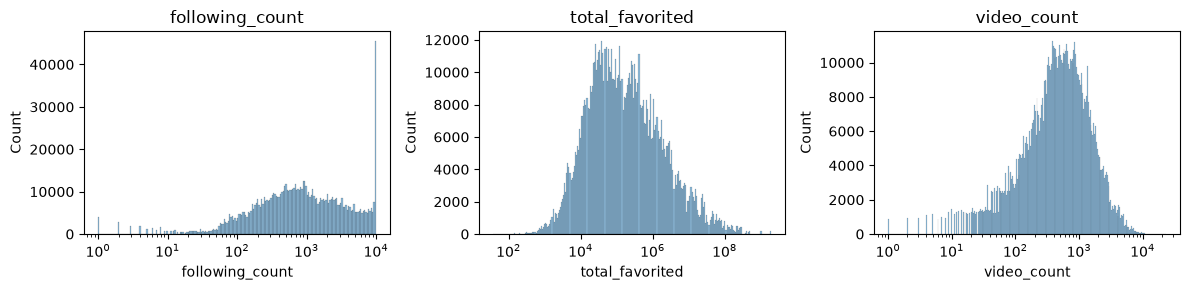

Video Count Describe
 count    931837.000000
mean        777.631460
std         981.744662
min           0.000000
25%         200.000000
50%         473.000000
75%         987.000000
max       23335.000000
Name: video_count, dtype: float64 


Total Favorited Describe
 count    9.335440e+05
mean     4.437269e+06
std      3.857325e+07
min      0.000000e+00
25%      2.968700e+04
50%      1.335425e+05
75%      8.245260e+05
max      1.953519e+09
Name: total_favorited, dtype: float64


In [9]:
cols = ["following_count", "total_favorited", "video_count"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, col in zip(axes, cols):
    sns.histplot(df_creators[col], log_scale=True, kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

print("Video Count Describe\n", df_creators["video_count"].describe(), "\n\n")
print("Total Favorited Describe\n", df_creators["total_favorited"].describe())

Заметим, что есть сильняя корреляция между ``total_favorited`` и ``follower_count``. Интерпретация такая: чем больше подписчиков у человека, тем больше вероятность, что его видео добавят в "Favorite". Остальные столбцы имеют слабую корреляцию, однако стоит заметить, что выборка креаторов после дедубликации не такая большая.

<Axes: >

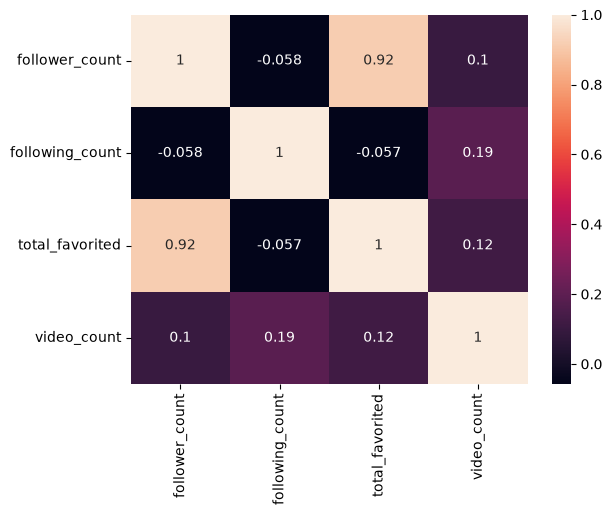

In [10]:
sns.heatmap(df_creators.select_dtypes(exclude="str").corr(), annot=True)

In [11]:
df_creators.isna().sum()

author_id             0
date                  0
follower_count     4452
following_count    4452
total_favorited    3940
video_count        5647
dtype: int64

### Videos

Это датасет с самими видео. В данном датасете все видео – уникальные, это проверяется в след. клетках удалением дубликатов

In [12]:
df_videos.shape

(1035817, 19)

In [13]:
df_videos = df_videos.drop_duplicates(subset=["video_id"], keep="last")

df_videos.shape

(1035817, 19)

In [14]:
df_videos.sample(4, random_state=RANDOM_STATE)

,video_id,author_id,create_time,create_date,duration,ratio,desc_language,is_english,desc,sticker_text,hashtags,created_by_ai,is_ads,music_selected_from,music_album,music_author,music_owner_id,music_id,music_title
153951,7392669932464524586,6849140798865900550,2024-07-17 13:15:05,2024-07-17,0.000,720p,un,0,NaN,NaN,[],0.0,0,edit_page_unfolded_category,Te Olvidaste de Mi,Luis Gonzalez El Bachatero,NaN,6807928615506823169,Te Olvidaste de Mi
240243,7400930389818117407,8350659,2024-08-08 19:29:54,2024-08-08,585.867,540p,en,1,Episode 2 Part 1 of 3 Web of Evil Shinzo #shin...,Episode 2 Part 1 of 3\nWeb of Evil Shinzo,"[{'hashtag_id': '12299', 'hashtag_name': 'game...",0.0,0,original,NaN,Cordero Vexacus Spencer,8350659,7400930362483919647,original sound - vexacus4666
876813,7466412517049355550,3324795,2025-02-01 05:36:45,2025-02-01,0.000,720p,en,1,Why is respect so powerful? Being respected by...,NaN,"[{'hashtag_id': '1643770238522374', 'hashtag_n...",0.0,0,edit_page_search,NaN,ALEXA RAE,227682125485944832,7240145032894876459,Bossy by Kelis
396882,7416318820480011550,7116966969319883819,2024-09-19 06:44:55,2024-09-19,12.470,540p,es,0,diversión,NaN,[],0.0,0,single_song,NaN,El Click De La Risa,7285550040495522821,7399338592507595525,original sound - elas.garcia1


In [15]:
df_videos.info()

<class 'pandas.DataFrame'>
RangeIndex: 1035817 entries, 0 to 1035816
Data columns (total 19 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   video_id             1035817 non-null  str    
 1   author_id            1035817 non-null  str    
 2   create_time          1035817 non-null  str    
 3   create_date          1035817 non-null  str    
 4   duration             1035817 non-null  float64
 5   ratio                1035817 non-null  str    
 6   desc_language        1035817 non-null  str    
 7   is_english           1035817 non-null  int64  
 8   desc                 843799 non-null   str    
 9   sticker_text         418306 non-null   str    
 10  hashtags             1035817 non-null  object 
 11  created_by_ai        1035813 non-null  float64
 12  is_ads               1035817 non-null  str    
 13  music_selected_from  1017504 non-null  str    
 14  music_album          242881 non-null   str    
 15  music_aut

``ratio`` – это качество видео.

Здесь его имеет смысл закодировать как ordinal, поскольку есть естественный способ задать отношение на множестве значений признака: 144p < 240p < 480p < ... < 2160p

In [16]:
df_videos["ratio"].value_counts()

ratio
540p     855406
720p     173751
480p       4658
360p       1931
1080p        46
240p         24
2160p         1
Name: count, dtype: int64

In [17]:
df_videos["ratio"] = df_videos["ratio"].replace({
    "240p": 0,
    "360p": 1,
    "480p": 2,
    "540p": 3,
    "720p": 4,
    "1080p": 5,
    "2160p": 6,
}).astype(np.uint8)

In [18]:
df_videos["ratio"].unique()

array([3, 2, 4, 1, 0, 5, 6], dtype=uint8)

In [19]:
df_videos.isna().sum()

video_id                    0
author_id                   0
create_time                 0
create_date                 0
duration                    0
ratio                       0
desc_language               0
is_english                  0
desc                   192018
sticker_text           617511
hashtags                    0
created_by_ai               4
is_ads                      0
music_selected_from     18313
music_album            792936
music_author             4292
music_owner_id         264804
music_id                 3013
music_title              3478
dtype: int64

Заметим, что ``desc`` – это просто описание видео, если оно None, можно просто приписать пустую строку.
Столбец ``created_by_ai`` содержит всего 4 пропуска, можно дропнуть строки содержащие их. 

Колонка ``sticker_text`` – это текст на экране видео, если его нет, тоже ставим пустую строку.
Колонка ``is_ads`` – всегда нулевая. С одной стороны, дропать ее нельзя, потому что, возможно, датасет собирался с условием что это не реклама. С другой стороны, пользы от него особо нет, при обучении модель не увидит паттерны с ``is_ads = 1``. Корреляцию тоже не построишь, потому что его $\sigma_{ads} = 0$

In [20]:
df_videos = df_videos.fillna(value={"desc": "", "sticker_text": ""})
df_videos["desc"].info()

df_videos = df_videos.dropna(subset=["created_by_ai"])
df_videos["is_ads"] = df_videos["is_ads"].astype(object) #чтобы в корреляции не было пустого столбца
print("Created by ai nones", df_videos["created_by_ai"].isna().sum())
print("Shape:", df_videos.shape)

<class 'pandas.Series'>
RangeIndex: 1035817 entries, 0 to 1035816
Series name: desc
Non-Null Count    Dtype
--------------    -----
1035817 non-null  str  
dtypes: str(1)
memory usage: 111.0 MB
Created by ai nones 0
Shape: (1035813, 19)


In [21]:
df_videos.is_ads.unique()

array(['0'], dtype=object)

Большая часть видео созданы именно человеком, что не даст модели обучиться на слоп

In [22]:
df_videos["created_by_ai"].value_counts()

created_by_ai
0.0    1031085
1.0       4728
Name: count, dtype: int64

Столбцы ``music_*`` ссылаются на звук, используемый на видео. 

``music_selected_from`` – откуда взят звук, 94 категории
``music_album`` – конкретный альбом.

К сожалению, на hugging face не было отдельного датасета со статистикой по каждому звуку, поэтому качественно использовать эту информацию пока что не получится.

In [23]:
df_videos.music_selected_from.nunique()

94

In [24]:
df_videos["is_ads"] = df_videos["is_ads"].astype(np.int8)
df_videos.isna().sum()

video_id                    0
author_id                   0
create_time                 0
create_date                 0
duration                    0
ratio                       0
desc_language               0
is_english                  0
desc                        0
sticker_text                0
hashtags                    0
created_by_ai               0
is_ads                      0
music_selected_from     18313
music_album            792932
music_author             4292
music_owner_id         264804
music_id                 3013
music_title              3478
dtype: int64

Дропнем ненужные колонки (в дальнейшем, если найдется способ получить аудио и выдернуть из него эмбеддинг, вернем): 
- ``music_*``
- ``is_ads``

In [25]:
df_videos = df_videos.drop(columns=["music_selected_from", "music_album", "music_author", "music_owner_id", "music_id", "music_title", "is_ads"])

In [26]:
# помогла нейронка
df_videos["hashtags"] = df_videos["hashtags"].apply(
    lambda hashtags: "\n".join(
        h["hashtag_name"]
        for h in hashtags
        if h["hashtag_name"] is not None
    ) if hashtags is not None else ""
)

In [27]:
df_videos.desc_language.nunique()

123

<Axes: >

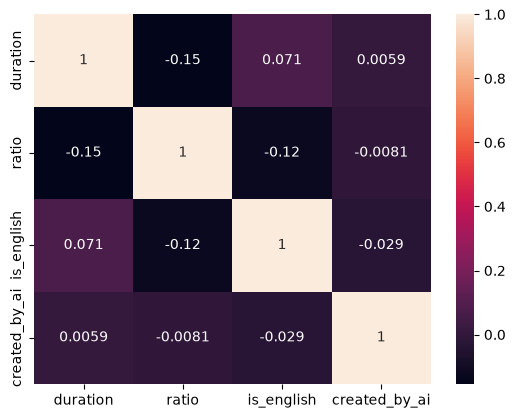

In [28]:
sns.heatmap(df_videos.select_dtypes(exclude="object").corr(), annot=True)

### Engagement

Основная статистика по видео: лайки, просмотры и тд

In [29]:
df_engagement

,video_id,date,days_since_post,play_count,like_count,comment_count,share_count,collect_count,download_count,whatsapp_share_count
0,7374877567083646254,2024-06-09,0,116320,7544,59,13,430,6,0
1,7374877567083646254,2024-06-10,1,336316,24863,106,47,1431,24,0
2,7374877567083646254,2024-06-11,2,456764,34936,128,60,1900,32,0
3,7374877567083646254,2024-06-12,3,525299,40024,146,68,2131,37,0
4,7374877567083646254,2024-06-13,4,563904,42623,150,78,2238,37,0
...,...,...,...,...,...,...,...,...,...,...
27169853,7484069902471515438,2025-03-20,0,39,1,0,0,0,0,0
27169854,7484070885310106926,2025-03-20,0,1,1,0,0,1,0,0
27169855,7484071175623085355,2025-03-20,0,0,0,0,0,0,0,0
27169856,7484072656187231518,2025-03-20,0,17,1,0,0,1,0,0


In [30]:
df_engagement.info()

<class 'pandas.DataFrame'>
RangeIndex: 27169858 entries, 0 to 27169857
Data columns (total 10 columns):
 #   Column                Dtype
---  ------                -----
 0   video_id              str  
 1   date                  str  
 2   days_since_post       int64
 3   play_count            int64
 4   like_count            int64
 5   comment_count         int64
 6   share_count           int64
 7   collect_count         int64
 8   download_count        int64
 9   whatsapp_share_count  int64
dtypes: int64(8), str(2)
memory usage: 2.8 GB


Заметим, что статистики популярности сильно друг с другом коррелируют.

<Axes: >

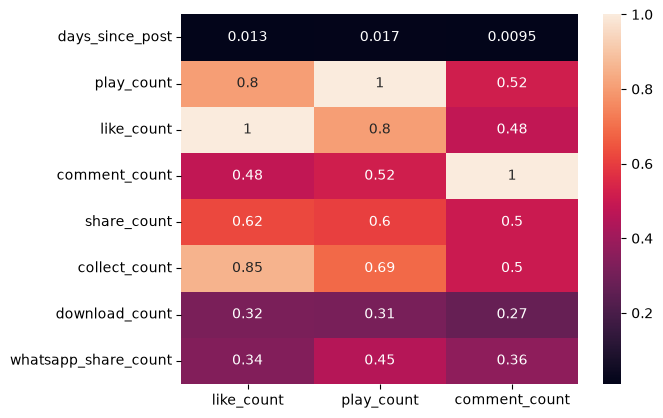

In [32]:
sns.heatmap(df_engagement.select_dtypes(exclude=["object", "str"]).corr()[["like_count", "play_count", "comment_count"]], annot=True)

# Все вместе

Джоиним все три таблицы. Логика такая: для каждого видео по ``author_id`` находим последний доступный снэпшот автора, предшествующий моменту публикаци ``create_time``. 

Используем ``merge_asof()`` с параметром ``direction="backward"``, чтобы исключить статистику автора из будущего и избежать утечки таргета

In [33]:
df_videos["create_time"] = pd.to_datetime(df_videos["create_time"])
df_creators["date"] = pd.to_datetime(df_creators["date"])

In [34]:
# помогла написать нейронка

engagement_cols = [
    "play_count",
    "like_count",
    "comment_count",
    "share_count",
    "collect_count",
    "download_count",
    "whatsapp_share_count",
]

day1 = df_engagement.loc[
    df_engagement["days_since_post"] == 1,
    ["video_id", "date", *engagement_cols]
].copy()

day7 = df_engagement.loc[df_engagement["days_since_post"] == 7, ["video_id", "play_count"]].copy()

assert day1["video_id"].is_unique
assert day7["video_id"].is_unique

day1 = day1.rename(columns={
    "date": "observation_date_1d",
    **{col: f"{col}_1d" for col in engagement_cols}
})

day7 = day7.rename(columns={
    "play_count": "target_views_7d"
})

df_all = day1.merge(
    day7,
    on="video_id",
    how="inner",
    validate="one_to_one"
)

При анализе выявлено 140 видео (0,02% выборки), для которых количество просмотров на седьмой день меньше, чем на первый. Поскольку доля таких наблюдений крайне мала, исключим их из итоговой обучающей выборки. Исходные данные при этом сохраним без изменений.

In [35]:
assert (
    df_all["target_views_7d"] >= df_all["play_count_1d"]
).all()

assert df_all["video_id"].is_unique

AssertionError: 

In [46]:
df_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 899839 entries, 0 to 899838
Data columns (total 26 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   video_id                 899839 non-null  str           
 1   observation_date_1d      899839 non-null  datetime64[us]
 2   play_count_1d            899839 non-null  int64         
 3   like_count_1d            899839 non-null  int64         
 4   comment_count_1d         899839 non-null  int64         
 5   share_count_1d           899839 non-null  int64         
 6   collect_count_1d         899839 non-null  int64         
 7   download_count_1d        899839 non-null  int64         
 8   whatsapp_share_count_1d  899839 non-null  int64         
 9   target_views_7d          899839 non-null  int64         
 10  author_id                899839 non-null  str           
 11  create_time              899839 non-null  datetime64[us]
 12  create_date              89

In [47]:
assert (
    pd.to_datetime(df_all["observation_date_7d"])
    - pd.to_datetime(df_all["observation_date_1d"])
    == pd.Timedelta(days=6)
).all()

KeyError: 'observation_date_7d'

In [36]:
invalid = df_all[
    df_all["target_views_7d"] < df_all["play_count_1d"]
]

print(f"Проблемных видео: {len(invalid):,}")
print(f"Доля: {len(invalid) / len(df_all):.2%}")

Проблемных видео: 140
Доля: 0.02%


In [37]:
df_all = df_all[
    df_all["target_views_7d"] >= df_all["play_count_1d"]
].copy()

In [38]:
assert (
    df_all["target_views_7d"] >= df_all["play_count_1d"]
).all()

assert df_all["video_id"].is_unique

"All good!"

'All good!'

In [39]:
df_all

,video_id,observation_date_1d,play_count_1d,like_count_1d,comment_count_1d,share_count_1d,collect_count_1d,download_count_1d,whatsapp_share_count_1d,target_views_7d
0,7374877567083646254,2024-06-10,336316,24863,106,47,1431,24,0,672163
1,7375243084034182446,2024-06-11,128135,11082,104,170,615,19,1,213792
2,7375243391107386666,2024-06-11,991688,84127,300,176,3828,59,3,2023183
3,7376376461986385182,2024-06-10,4,1,0,0,0,0,0,7
4,7376431416839507242,2024-06-10,316,14,0,1,1,0,0,454
...,...,...,...,...,...,...,...,...,...,...
899978,7481524746258042158,2025-03-14,539,78,6,0,2,1,0,834
899979,7481524852126469407,2025-03-14,153,1,0,0,0,0,0,207
899980,7481524883445386538,2025-03-14,190,9,0,0,1,0,0,317
899981,7481525018799672622,2025-03-14,465,47,0,0,1,0,0,676


## Формирование обучающей выборки

Для решения задачи Early Popularity Prediction объединим три датасета. Из ``df_engagement`` извлечём статистику первого дня (day1) и количество просмотров на седьмой день (day7). Объединим их по ``video_id``. Таким образом, каждая строка будет соответствовать одному видео, а ``target_views_7d`` станет целевой переменной. Добавим метаданные видео из ``df_videos``. С помощью ``merge_asof()`` присоединим последний доступный снэпшот автора, предшествующий наблюдению первого дня.

Используем ``direction="backward"``, чтобы не включать статистику автора из будущего и снизить риск утечки.

В результате получим датасет, содержащий признаки, доступные на первый день наблюдения, и целевую переменную, отражающую количество просмотров на седьмой день.

In [40]:
df_creators

,author_id,date,follower_count,following_count,total_favorited,video_count
0,1008189,2024-07-11,1168.0,432.0,1687.0,89.0
1,1008189,2024-07-12,1167.0,432.0,1693.0,90.0
2,1008189,2024-07-13,1165.0,432.0,1693.0,90.0
3,1008189,2024-07-14,1164.0,432.0,1693.0,90.0
4,1008189,2024-07-15,1164.0,433.0,1693.0,90.0
...,...,...,...,...,...,...
937479,984282,2025-01-14,142518.0,201.0,1870366.0,115.0
937480,984282,2025-01-15,142515.0,202.0,1870370.0,115.0
937481,984282,2025-01-16,142510.0,202.0,1870378.0,115.0
937482,984282,2025-01-17,142505.0,202.0,1870384.0,115.0


In [ ]:
df_all["observation_date_1d"] = pd.to_datetime(df_all["observation_date_1d"])

df_creators["date"] = pd.to_datetime(df_creators["date"])

creator_cols = [
    "author_id",
    "date",
    "follower_count",
    "following_count",
    "total_favorited",
    "video_count",
]
df_all = df_all.merge(
    df_videos,
    on="video_id",
    how="inner",
    validate="one_to_one"
)

# функцию помогла написать нейронка
df_all = pd.merge_asof(
    df_all.sort_values("observation_date_1d"),
    df_creators[creator_cols].sort_values("date"),
    left_on="observation_date_1d",
    right_on="date",
    by="author_id",
    direction="backward",
    allow_exact_matches=False
)

df_all.shape

(899839, 26)

In [51]:
df_all.isna().sum().sum()

np.int64(1355)

Дропнем оставшиеся Null, так как их мало.

In [52]:
df_all = df_all.dropna()

Примерно 10% датасета составляют "видео", в которых длительность = 0. Это, на самом деле, не баг, а это "видео" из слайдшоу. Самый первый такой пример: https://www.tiktok.com/@_2xtae/photo/7378642407681805611?image_index=2. Пока нет возможности работать с фотографиями.

In [60]:
df_all[df_all.duration == 0][["duration", "video_id", "author_id"]].head(1)

,duration,video_id,author_id
6,0.0,7378642407681805611,6790523149998998534


In [63]:
df_all["is_slideshow"] = (df_all.duration == 0).astype(np.int8)

По данным матрицы корреляции можно увидеть, что статистика просмотров за первые сутки сильно коррелирует с тем что происходит на 7 сутки. Это значит, что в качестве бейзлана можно брать лин. рег.

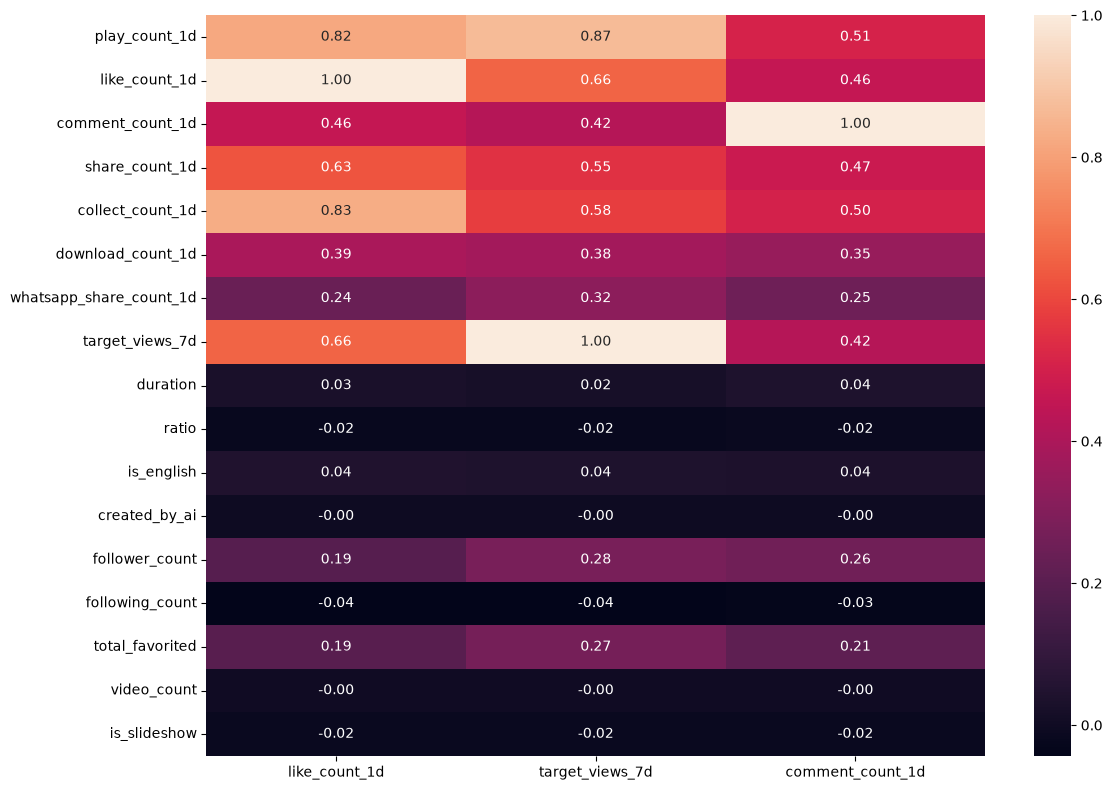

In [64]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_all.select_dtypes(include="number").corr()[["like_count_1d", "target_views_7d", "comment_count_1d"]],
    annot=True,
    fmt=".2f",
)

plt.tight_layout()
plt.show()

# Основные выводы по данным

1. Распределения характеристик авторов и видео неравномерны. Статистика авторов имеет выраженную асимметрию: большинство наблюдений приходится на аккаунты с относительно небольшими показателями, тогда как отдельные аккаунты достигают значительно больших значений.

2. Между показателями вовлечённости наблюдаются положительные корреляции. Количество просмотров, лайков, комментариев и других взаимодействий связано между собой. Это позволяет предположить, что ранняя статистика вовлечённости может быть полезна для прогнозирования дальнейшей популярности видео.

3. Большинство видео имеют разрешение 540p или 720p. Остальные значения разрешения встречаются значительно реже, поэтому влияние этого признака на популярность видео ещё предстоит исследовать.

4. В данных присутствуют пропуски и аномалии. В статистике авторов обнаружены пропущенные значения, которые могут быть связаны с недоступностью отдельных аккаунтов или ошибками сбора данных.

5. 10% датасета составляют "слайдшоу"

6. Датасет подходит для задачи Early Popularity Prediction. Из примерно 1 млн видео для 899 983 доступны наблюдения как первого, так и 7 дня. Покрытие составляет 93% относительно видео с наблюдением первого дня. Это позволяет сформировать обучающую выборку для регрессии, где признаки представлены статистикой первого дня и метаданными видео, а целевая переменная количеством просмотров на седьмой день.
